# BikeNodePlanner–dk_bicycle_network LTS combination
The main workflow keeps the original sample-point matching loop. `SEGMENT_LENGTH_M` controls the preview, segment split, and segment map; `MAX_LTS_PLOT_SETTING` independently controls the maximum-per-link map.

The full `SEGMENT_LENGTH_M_LIST` is used only in the comparison-table cell near the end. The regional-table update is in its own cell. Only the maximum map and selected segment map are saved. The original `combine_bornholm.ipynb` is not changed.

Environment: the unchanged spatial-index loop needs a GeoPandas version supporting `query(..., predicate="dwithin", distance=...)`. This copy was verified with GeoPandas 1.1.3; GeoPandas 0.14.4 in the older `dk_bike_network` environment does not support the `distance` argument. Select a compatible notebook kernel.


## Setup

In [39]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from IPython.display import display
from shapely.geometry import box

working_dir = Path.cwd().resolve()

PROJECT_ROOT = working_dir.parent if working_dir.name == "combine" else working_dir  # this notebook lives in bike_safety/combine/

# Output folders for this notebook
COMBINE_DIR = PROJECT_ROOT / "combine"
DATA_OUTPUT_DIR = COMBINE_DIR / "data"
PLOTS_OUTPUT_DIR = COMBINE_DIR / "plots"

# DK_bicycle_network with LTS, produced by dk_bicycle_network (script 11)
DK_NETWORK_EDGES_PATH = PROJECT_ROOT / "dk_bicycle_network/data/processed/osm_road_edges.parquet"

EXTRACTION_MARGIN_M = 500  # only needs to exceed TOLERANCE_M
TOLERANCE_M = 10           # max distance between a bike-loop link and an OSM edge

SEGMENT_LENGTH_M_LIST = ["include all segments", 0.1, 0.5, 1, 2, 5, 10, 15, 20, 50, 100, 200]
SEGMENT_LENGTH_M = 1      # preview and segment-map spacing, in metres

SHOW_INTERACTIVE_MAP = True  # display the selected result interactively

# Columns needed from the dk_bicycle_network edges
OSM_COLUMNS = [ "lts", "cycling_allowed", "geometry"]

# LTS 999 = no cycling (pedestrian paths). LTS 0 = car-free paths where cycling is allowed.
EXCLUDED_LTS = [999]
LTS_0_AS = 1  # research choice: treat car-free paths as low stress

In [40]:
# view DK_NETWORK_EDGES_PATH parquet file:
df = pd.read_parquet(DK_NETWORK_EDGES_PATH)
df.head()

,highway,name,bicycle_category_dk,cycling_allowed,car_traffic,along_street,lit,cycleway_segregated,car_oneway,bike_oneway,...,y1,x2,y2,source,target,km,kmh,cost,reverse_cost,geometry
0,track,None,None,True,True,True,None,None,False,False,...,55.252929,10.066217,55.252731,948855,948856,0.082111,15,1.231663,1.231663,b'\x01\x02\x00\x00\x00\x02\x00\x00\x00\x0f?mN\...
1,service,None,None,True,True,True,None,None,False,False,...,55.803847,9.695109,55.804169,1322310,1322311,0.035971,15,0.539572,0.539572,b'\x01\x02\x00\x00\x00\x02\x00\x00\x00\xc3\x04...
2,service,None,None,True,True,True,None,None,False,False,...,55.544094,12.132774,55.544080,1198881,1198882,0.064783,15,0.971746,0.971746,b'\x01\x02\x00\x00\x00\x02\x00\x00\x00=\xf2\x8...
3,service,None,None,True,True,True,None,None,False,False,...,56.274759,9.731196,56.274807,704236,704233,0.005884,15,0.088255,0.088255,b'\x01\x02\x00\x00\x00\x02\x00\x00\x00\xf5[\xd...
4,residential,None,None,True,True,True,None,None,False,False,...,55.494705,9.736546,55.494722,128826,128827,0.010556,15,0.158334,0.158334,b'\x01\x02\x00\x00\x00\x02\x00\x00\x00h)7k\xe0...


In [41]:
# find row corresponding to the shortest segment 
min_row = df.loc[df['km'].idxmin()]
# what is the length of the shortest segment in meters?
min_length_m = min_row['km'] * 1000
print(f"The shortest segment is {min_length_m:.5f} meters long.")
min_row

The shortest segment is 0.01113 meters long.


highway                                                                      service
name                                                                            None
bicycle_category_dk                                                             None
cycling_allowed                                                                 True
car_traffic                                                                     True
along_street                                                                    True
lit                                                                              yes
cycleway_segregated                                                             None
car_oneway                                                                      True
bike_oneway                                                                     True
bikeinfra_both_sides                                                           False
maxspeed                                                         

#### Inspect a segment

In [58]:
"""with pd.option_context("display.max_columns", None):
    display(
        df[
            (df["lts"] == 4)
            & (df["municipality"] == "Bornholm")
            & (df["name"] == "Helligdomsvej")
        ]
    )"""

'with pd.option_context("display.max_columns", None):\n    display(\n        df[\n            (df["lts"] == 4)\n            & (df["municipality"] == "Bornholm")\n            & (df["name"] == "Helligdomsvej")\n        ]\n    )'

In [43]:
df.describe()

,maxspeed,lanes,bicycle_class,lts,id,osm_id,x1,y1,x2,y2,source,target,km,kmh,cost,reverse_cost
count,1.646987e+06,1.905775e+06,1.961004e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2.533464e+06,2533464.0,2.533464e+06,2.533464e+06
mean,5.253239e+01,1.848302e+00,2.702914e+00,1.897266e+02,1.266732e+06,4.833891e+08,2.290142e+02,2.332474e+03,2.290147e+02,2.332474e+03,9.822245e+05,9.910395e+05,7.890372e-02,15.0,1.183556e+00,1.183556e+00
std,1.446301e+01,3.901665e-01,6.945541e-01,3.899348e+02,7.313482e+05,4.736048e+08,1.150063e+04,1.186802e+05,1.150065e+04,1.186802e+05,5.891882e+05,5.870126e+05,1.435940e-01,0.0,2.153909e+00,2.153909e+00
min,5.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,2.080000e+03,8.076097e+00,5.455935e+01,8.076097e+00,5.455935e+01,1.000000e+00,1.000000e+00,1.113079e-05,15.0,1.669618e-04,1.669618e-04
25%,5.000000e+01,2.000000e+00,3.000000e+00,1.000000e+00,6.333668e+05,9.682108e+07,9.498752e+00,5.547791e+01,9.498804e+00,5.547790e+01,4.645398e+05,4.762668e+05,1.484577e-02,15.0,2.226865e-01,2.226865e-01
50%,5.000000e+01,2.000000e+00,3.000000e+00,2.000000e+00,1.266732e+06,2.563013e+08,1.018622e+01,5.576204e+01,1.018623e+01,5.576207e+01,9.662115e+05,9.831185e+05,3.507395e-02,15.0,5.261093e-01,5.261093e-01
75%,5.000000e+01,2.000000e+00,3.000000e+00,4.000000e+00,1.900098e+06,8.607597e+08,1.191590e+01,5.621958e+01,1.191607e+01,5.621961e+01,1.492370e+06,1.498127e+06,7.936187e-02,15.0,1.190428e+00,1.190428e+00
max,1.300000e+02,1.900000e+01,3.000000e+00,9.990000e+02,2.533464e+06,1.565632e+09,8.699546e+05,6.399844e+06,8.699818e+05,6.399844e+06,2.025463e+06,2.025464e+06,9.790719e+00,15.0,1.468608e+02,1.468608e+02


## Load dk_bicycle_network edges (once for all of Denmark)

In [44]:
### Time: ≈ 1 min
dk_edges_dk = gpd.read_parquet(DK_NETWORK_EDGES_PATH, columns=OSM_COLUMNS)

dk_edges_dk = dk_edges_dk.loc[
    dk_edges_dk["cycling_allowed"] & ~dk_edges_dk["lts"].isin(EXCLUDED_LTS)
].copy()
dk_edges_dk["lts"] = dk_edges_dk["lts"].replace(0, LTS_0_AS)

print(f"dk_bicycle_network edges with cycling allowed: {len(dk_edges_dk):,}")
print("CRS:", dk_edges_dk.crs.to_string())
display(dk_edges_dk["lts"].value_counts().sort_index().to_frame("edges"))

dk_bicycle_network edges with cycling allowed: 1,961,004
CRS: EPSG:25832


,edges
lts,
1,679932
2,944285
3,216293
4,120494


# Bornholm

In [45]:
SAMPLE = "bornholm"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
DATA_DIR = DATA_OUTPUT_DIR / SAMPLE
PLOTS_DIR = PLOTS_OUTPUT_DIR / SAMPLE
OUTPUT_PATH = DATA_DIR / "edges_slope_lts.gpkg"
OUTPUT_SEGMENTS_PATH = DATA_DIR / "edges_lts_segments.gpkg"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Data output folder:", DATA_DIR)
print("Plots output folder:", PLOTS_DIR)

Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/bornholm/network/processed
Data output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/data/bornholm
Plots output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/plots/bornholm


In [46]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

if bike_loops_edges.crs != dk_edges_dk.crs:
    raise ValueError("Bike-loop edges and dk_bicycle_network edges have different CRS.")

print(f"Bike loop edges: {len(bike_loops_edges):,}")

Bike loop edges: 89


### Extract area of interest from dk_bicycle_network

In [47]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

dk_edges = dk_edges_dk.cx[
    minx - EXTRACTION_MARGIN_M : maxx + EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M : maxy + EXTRACTION_MARGIN_M,
].copy()

print(f"dk_bicycle_network edges in {SAMPLE}: {len(dk_edges):,}")

dk_bicycle_network edges in bornholm: 25,240


### Match LTS onto the bike-loop links

In [48]:
dk_spatial_index = dk_edges.sindex
dk_geometries = dk_edges.geometry.to_numpy()
dk_lts = dk_edges["lts"].to_numpy()

max_lts_values, coverage_pcts, lts_shares = [], [], []
point_lts_per_link = []  # LTS at every sample point, used to split links into parts
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):
    # Sample points along the link, every SEGMENT_LENGTH_M
    distances = np.arange(0, geometry.length, SEGMENT_LENGTH_M)
    points = shapely.line_interpolate_point(geometry, distances)

    # Find only OSM lines within the matching tolerance
    candidate_positions = dk_spatial_index.query(
        geometry,
        predicate="dwithin",
        distance=TOLERANCE_M,
    )
    candidate_positions = np.unique(candidate_positions)

    # Lowest LTS within TOLERANCE_M of each point (inf = no match)
    point_lts = np.full(len(points), np.inf)
    if len(candidate_positions) > 0:
        candidate_geometries = dk_geometries[candidate_positions]
        is_near = shapely.dwithin(candidate_geometries[:, None], points[None, :], TOLERANCE_M)
        candidate_lts = dk_lts[candidate_positions].astype(float)
        point_lts = np.where(is_near, candidate_lts[:, None], np.inf).min(axis=0)

    point_lts_per_link.append(point_lts)
    matched_lts = point_lts[np.isfinite(point_lts)]

    max_lts_values.append(matched_lts.max() if len(matched_lts) else np.nan)
    coverage_pcts.append(100 * len(matched_lts) / len(points))
    lts_shares.append([100 * np.mean(point_lts == lts) for lts in (1, 2, 3, 4)])

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Matching completed.


In [49]:
bike_loops_lts = bike_loops_edges.copy()
bike_loops_lts["max_lts"] = max_lts_values
bike_loops_lts["coverage_pct"] = coverage_pcts
bike_loops_lts[["lts1_pct", "lts2_pct", "lts3_pct", "lts4_pct"]] = lts_shares

display(bike_loops_lts[["edge_id", "mm_len", "max_lts", "coverage_pct", "lts1_pct", "lts2_pct", "lts3_pct", "lts4_pct"]].describe().round(1))
display(bike_loops_lts["max_lts"].value_counts(dropna=False).sort_index().to_frame("links"))

,edge_id,mm_len,max_lts,coverage_pct,lts1_pct,lts2_pct,lts3_pct,lts4_pct
count,89.0,89.0,89.0,89.0,89.0,89.0,89.0,89.0
mean,44.0,4221.7,3.1,99.0,38.0,8.1,40.8,12.1
std,25.8,2764.4,1.0,2.8,40.0,16.7,38.7,24.8
min,0.0,6.6,1.0,87.1,0.0,0.0,0.0,0.0
25%,22.0,2399.9,3.0,100.0,1.2,0.0,1.1,0.0
50%,44.0,3688.1,3.0,100.0,18.5,1.4,26.3,0.0
75%,66.0,5931.1,4.0,100.0,80.0,6.5,79.0,8.2
max,88.0,11040.8,4.0,100.0,100.0,91.6,100.0,94.9


,links
max_lts,
1.0,11
2.0,6
3.0,38
4.0,34


## Split links into LTS segments

The links are kept as they are, but every time the LTS changes along a link, a new segment starts. Each segment records where on the link it is (`from_m`, `to_m`, measured along the link's geometry from its start) and its LTS.

- A sample point covers `SEGMENT_LENGTH_M / 2` on either side, so a change between two points is placed halfway between them.
- The first segment starts at 0 and the last segment ends at the link's full length.
- Stretches with no dk_bicycle_network edge within `TOLERANCE_M` become segments with an empty `lts`.
- `link_id` is the link's row number in the input file. It connects each segment to its link (in `combine_denmark`, `edge_id` is not unique, so `edge_id` alone is not enough).

In [50]:
from shapely.ops import substring

bike_loops_lts["link_id"] = bike_loops_lts.index

segments = []

for (link_id, link), point_lts in zip(bike_loops_lts.iterrows(), point_lts_per_link):
    geometry = link.geometry
    distances = np.arange(0, geometry.length, SEGMENT_LENGTH_M)

    # Positions where the LTS differs from the previous point
    change_positions = np.flatnonzero(point_lts[1:] != point_lts[:-1]) + 1
    run_starts = np.r_[0, change_positions]
    run_ends = np.r_[change_positions, len(point_lts)]  # first point after the run

    for segment_number, (start, end) in enumerate(zip(run_starts, run_ends), start=1):
        from_m = 0.0 if start == 0 else distances[start] - SEGMENT_LENGTH_M / 2
        to_m = geometry.length if end == len(point_lts) else distances[end] - SEGMENT_LENGTH_M / 2
        lts = point_lts[start]

        segments.append({
            "link_id": link_id,
            "edge_id": link["edge_id"],
            "node_start": link["node_start"],
            "node_end": link["node_end"],
            "segment": segment_number,
            "from_m": from_m,
            "to_m": to_m,
            "length_m": to_m - from_m,
            "lts": lts if np.isfinite(lts) else np.nan,
            "geometry": substring(geometry, from_m, to_m),
        })

bike_loops_lts_segments = gpd.GeoDataFrame(segments, geometry="geometry", crs=bike_loops_lts.crs)

print(f"{len(bike_loops_lts_segments):,} segments on {len(bike_loops_lts):,} links")

1,232 segments on 89 links


In [51]:
# Check: the segments of each link add up to the link's length
length_difference = (
    bike_loops_lts_segments.groupby("link_id")["length_m"].sum()
    - bike_loops_lts.geometry.length
)
print(f"Largest difference between summed segments and link length: {length_difference.abs().max():.6f} m")

print("Segments per link:")
display(bike_loops_lts_segments.groupby("link_id").size().describe().round(1).to_frame("segments"))

print("Segment lengths (m):")
display(bike_loops_lts_segments["length_m"].describe().round(1).to_frame("length_m"))

print("Total length per LTS (km):")
display(
    bike_loops_lts_segments.groupby("lts", dropna=False)["length_m"].sum()
    .div(1000).round(1).to_frame("km")
)

# Example: the link with the most segments
example_link_id = bike_loops_lts_segments.groupby("link_id").size().idxmax()
print(f"Example, link_id {example_link_id}:")
display(
    bike_loops_lts_segments.loc[bike_loops_lts_segments["link_id"] == example_link_id]
    .drop(columns="geometry").round(1)
)

Largest difference between summed segments and link length: 0.000000 m
Segments per link:


,segments
count,89.0
mean,13.8
std,15.4
min,1.0
25%,4.0
50%,10.0
75%,18.0
max,87.0


Segment lengths (m):


,length_m
count,1232.0
mean,305.0
std,660.7
min,1.0
25%,20.0
50%,34.0
75%,289.5
max,6413.0


Total length per LTS (km):


,km
lts,
1.0,155.0
2.0,27.1
3.0,138.3
4.0,50.5
NaN,4.8


Example, link_id 85:


,link_id,edge_id,node_start,node_end,segment,from_m,to_m,length_m,lts
1115,85,85,54,57,1,0.0,16.5,16.5,1.0
1116,85,85,54,57,2,16.5,105.5,89.0,4.0
1117,85,85,54,57,3,105.5,125.5,20.0,1.0
1118,85,85,54,57,4,125.5,258.5,133.0,4.0
1119,85,85,54,57,5,258.5,278.5,20.0,1.0
...,...,...,...,...,...,...,...,...,...
1197,85,85,54,57,83,6454.5,6524.5,70.0,3.0
1198,85,85,54,57,84,6524.5,6552.5,28.0,2.0
1199,85,85,54,57,85,6552.5,6575.5,23.0,3.0
1200,85,85,54,57,86,6575.5,6576.5,1.0,2.0


In [59]:
if SHOW_INTERACTIVE_MAP:
    # Fixed LTS 1–4 colours stay consistent even if a class is absent.
    lts_map = bike_loops_lts_segments.explore(
        column="lts",
        categorical=True,
        categories=[1, 2, 3, 4],
        cmap=["#0072B2", "#7B3294", "#E66101", "#B2182B"],
        tiles="OpenStreetMap",
        style_kwds={"weight": 4, "opacity": 1},
        highlight_kwds={"weight": 7},
        missing_kwds={"color": "#555555", "label": "No match"},
        tooltip=["lts", "length_m"],
        tooltip_kwds={"aliases": ["LTS score", "Segment length (m)"], "localize": True},
    )
    display(lts_map)


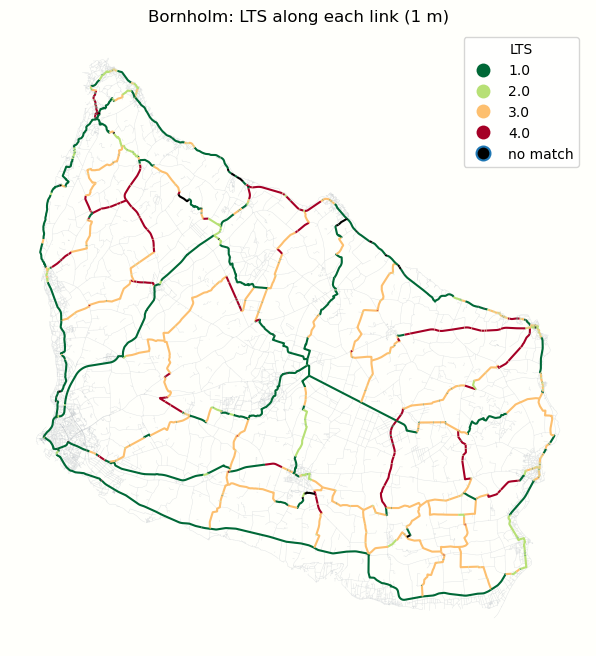

In [53]:
fig, ax = plt.subplots(figsize=(8, 8), facecolor="#fffffb")

dk_edges.plot(ax=ax, color="#c8cdd2", linewidth=0.3, alpha=0.6, zorder=1)
bike_loops_lts_segments.plot(
    ax=ax,
    column="lts",
    categorical=True,
    cmap="RdYlGn_r",
    linewidth=1.5,
    legend=True,
    legend_kwds={"title": "LTS"},
    missing_kwds={"color": "black", "label": "no match"},
    zorder=2,
)
ax.set_title(f"{SAMPLE.title()}: LTS along each link ({SEGMENT_LENGTH_M:g} m)")
ax.set_axis_off()
fig.savefig(PLOTS_DIR / f"loops_lts_{SEGMENT_LENGTH_M:g}m.png", dpi=300, bbox_inches="tight")
plt.show()

In [54]:
# Save only the selected setting, as in the original notebook.
# Convert pandas string columns for compatibility with older Fiona versions.
for frame, output_path in [(bike_loops_lts, OUTPUT_PATH), (bike_loops_lts_segments, OUTPUT_SEGMENTS_PATH)]:
    output = frame.copy()
    for column in output.columns:
        if isinstance(output[column].dtype, pd.StringDtype):
            output[column] = output[column].astype(object)
    output.to_file(output_path, driver="GPKG")
    print("Saved:", output_path)

Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/data/bornholm/edges_slope_lts.gpkg
Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/data/bornholm/edges_lts_segments.gpkg


## Segment distance comparison
Run this single cell to calculate and save `segment_length_comparison.csv` for `SEGMENT_LENGTH_M_LIST`. It does not change `SEGMENT_LENGTH_M`, the selected links/segments, or the maps. It saves no additional maps or per-setting GeoPackages.

In [55]:
# This cell alone calculates and saves the sampling-distance comparison.
# Numeric settings use the original sample-point rule; all-segments mode uses
# tolerance-buffer intersections (polygonal approximations, quad_segs=64).
from collections import defaultdict
from itertools import groupby

def build_segment_length_comparison():
    dk_geometries = dk_edges.geometry.to_numpy()
    dk_lts = dk_edges["lts"].to_numpy(dtype=float)
    dk_tree = shapely.STRtree(dk_geometries)
    road_buffer_cache = {}
    BUFFER_QUAD_SEGS = 64
    POINT_BATCH_SIZE = 8192

    def merge_intervals(intervals):
        """Merge adjacent equal-score intervals, including adjacent unmatched intervals."""
        merged = []
        for start, end, score in intervals:
            if end <= start:
                continue
            if merged and score == merged[-1][2] and start == merged[-1][1]:
                merged[-1] = (merged[-1][0], end, score)
            else:
                merged.append((start, end, score))
        return merged

    def sampled_intervals(geometry, spacing):
        distances = np.arange(0, geometry.length, spacing)
        scores = np.full(len(distances), np.inf)
        for offset in range(0, len(distances), POINT_BATCH_SIZE):
            points = shapely.line_interpolate_point(geometry, distances[offset:offset + POINT_BATCH_SIZE])
            point_ids, road_ids = dk_tree.query(points, predicate="dwithin", distance=TOLERANCE_M)
            np.minimum.at(scores, offset + point_ids, dk_lts[road_ids])
        changes = np.flatnonzero(scores[1:] != scores[:-1]) + 1
        starts = np.r_[0, changes]
        ends = np.r_[changes, len(scores)]
        intervals = [
            (0.0 if start == 0 else float((distances[start - 1] + distances[start]) / 2),
             float(geometry.length) if end == len(scores) else float((distances[end - 1] + distances[end]) / 2),
             float(scores[start]))
            for start, end in zip(starts, ends)
        ]
        return intervals, scores

    def line_components(geometry):
        if geometry.geom_type == "LineString":
            yield geometry
        elif geometry.geom_type in ("MultiLineString", "GeometryCollection"):
            for component in geometry.geoms:
                yield from line_components(component)

    def all_segments_intervals(geometry):
        events = [(0.0, None, 0), (float(geometry.length), None, 0)]
        candidates = dk_tree.query(geometry, predicate="dwithin", distance=TOLERANCE_M)
        for road_id in candidates:
            road_id = int(road_id)
            if road_id not in road_buffer_cache:
                road_buffer_cache[road_id] = shapely.buffer(
                    dk_geometries[road_id], TOLERANCE_M, quad_segs=BUFFER_QUAD_SEGS
                )
            intersection = geometry.intersection(road_buffer_cache[road_id])
            for component in line_components(intersection):
                start, end = sorted((
                    float(geometry.project(shapely.Point(component.coords[0]))),
                    float(geometry.project(shapely.Point(component.coords[-1]))),
                ))
                start, end = max(0.0, start), min(float(geometry.length), end)
                if end > start:
                    events.extend([(start, float(dk_lts[road_id]), 1), (end, float(dk_lts[road_id]), -1)])
        events.sort(key=lambda event: event[0])
        grouped_events = [(distance, list(group)) for distance, group in groupby(events, key=lambda event: event[0])]
        active = defaultdict(int)
        intervals = []
        for i, (start, group) in enumerate(grouped_events[:-1]):
            for _, score, delta in group:
                if score is not None:
                    active[score] += delta
            end = grouped_events[i + 1][0]
            score = min((score for score, count in active.items() if count > 0), default=np.inf)
            intervals.append((start, end, score))
        return merge_intervals(intervals)

    rows = []
    total_length = bike_loops_edges.length.sum()
    for setting in SEGMENT_LENGTH_M_LIST:
        segment_count = 0
        class_lengths = {score: 0.0 for score in (1, 2, 3, 4)}
        for geometry in bike_loops_edges.geometry:
            if setting == "include all segments":
                if not geometry.is_simple:
                    raise ValueError("All-segments comparison requires links without self-intersections.")
                intervals = all_segments_intervals(geometry)
            else:
                if not isinstance(setting, (int, float)) or not np.isfinite(setting) or setting <= 0:
                    raise ValueError(f"Invalid segment length: {setting!r}")
                intervals, _ = sampled_intervals(geometry, float(setting))
            segment_count += len(intervals)
            for start, end, score in intervals:
                if score in class_lengths:
                    class_lengths[score] += end - start
        rows.append({
            "setting": str(setting),
            "segment_length_m": np.nan if setting == "include all segments" else float(setting),
            "links": len(bike_loops_edges), "segments": segment_count,
            "total_length_km": total_length / 1000,
            "matched_length_pct": 100 * sum(class_lengths.values()) / total_length,
            **{f"lts{score}_length_pct": 100 * length / total_length for score, length in class_lengths.items()},
        })
        print(f"{setting}: {segment_count:,} segments", flush=True)
    return pd.DataFrame(rows)

comparison = build_segment_length_comparison()
COMPARISON_PATH = DATA_DIR / "segment_length_comparison.csv"
comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison.round(3))
print("Saved:", COMPARISON_PATH)

include all segments: 1,247 segments
0.1: 1,236 segments
0.5: 1,233 segments
1: 1,232 segments
2: 1,223 segments
5: 1,214 segments
10: 1,174 segments
15: 1,150 segments
20: 1,113 segments
50: 620 segments
100: 453 segments
200: 339 segments


,setting,segment_length_m,links,segments,total_length_km,matched_length_pct,lts1_length_pct,lts2_length_pct,lts3_length_pct,lts4_length_pct
0,include all segments,NaN,89,1247,375.732,98.723,41.255,7.207,36.822,13.439
1,0.1,0.1,89,1236,375.732,98.723,41.255,7.208,36.822,13.439
2,0.5,0.5,89,1233,375.732,98.723,41.255,7.209,36.821,13.439
3,1,1.0,89,1232,375.732,98.723,41.253,7.211,36.819,13.440
4,2,2.0,89,1223,375.732,98.724,41.253,7.209,36.822,13.441
5,5,5.0,89,1214,375.732,98.722,41.254,7.209,36.824,13.435
6,10,10.0,89,1174,375.732,98.720,41.244,7.228,36.809,13.440
7,15,15.0,89,1150,375.732,98.699,41.230,7.162,36.870,13.436
8,20,20.0,89,1113,375.732,98.713,41.243,7.189,36.828,13.453
9,50,50.0,89,620,375.732,98.689,41.215,7.083,36.848,13.544


Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/data/bornholm/segment_length_comparison.csv


## Shared regional segment summary
Run this single cell to update Bornholm's row in `DATA_OUTPUT_DIR / "region_segment_length_summary.csv"`. It reads the saved comparison table and preserves the other regions' rows.

In [56]:
# This cell alone updates this region's row in the shared regional table.
# It can also be rerun using a previously saved comparison CSV.
region_comparison = pd.read_csv(DATA_DIR / "segment_length_comparison.csv")
REGION_SUMMARY_PATH = DATA_OUTPUT_DIR / "region_segment_length_summary.csv"
region_source_path = REGION_SUMMARY_PATH
if not region_source_path.exists():
    region_source_path = DATA_OUTPUT_DIR / "lts_segments_by_region.csv"
region_segment_length_summary = (
    pd.read_csv(region_source_path, index_col="Region") if region_source_path.exists()
    else pd.DataFrame(index=pd.Index([], name="Region"))
)
region_name = SAMPLE.replace("_", " ").title()
region_counts = region_comparison.set_index("setting")["segments"]
region_columns = list(dict.fromkeys([*region_segment_length_summary.columns, *region_counts.index]))
region_rows = list(dict.fromkeys([*region_segment_length_summary.index, region_name]))
region_segment_length_summary = region_segment_length_summary.reindex(index=region_rows, columns=region_columns)
region_segment_length_summary.loc[region_name, region_counts.index] = region_counts.to_numpy()
region_segment_length_summary = region_segment_length_summary.astype("Int64")
region_segment_length_summary.index.name = "Region"
region_segment_length_summary.to_csv(REGION_SUMMARY_PATH)
display(region_segment_length_summary)
print("Saved:", REGION_SUMMARY_PATH)

,include all segments,0.1,0.5,1,2,5,10,15,20,50,100,200
Region,,,,,,,,,,,,
Bornholm,1247,1236,1233,1232,1223,1214,1174,1150,1113,620,453,339


Saved: /Users/ellenebdrup/Documents/GitHub/bike_safety/combine/data/region_segment_length_summary.csv


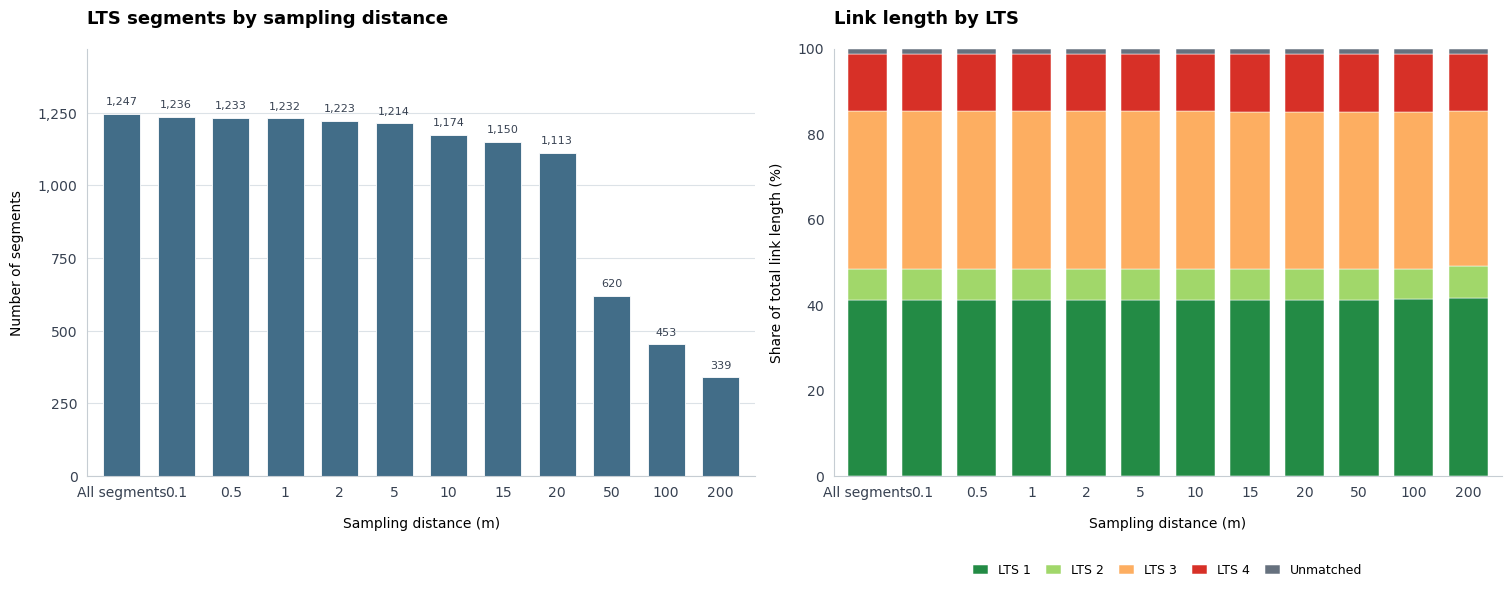

In [57]:
from matplotlib.ticker import MaxNLocator, MultipleLocator, StrMethodFormatter

# Keep these charts inline; only the two selected maps are saved to plots/.
setting_labels = [
    "All segments" if str(setting) == "include all segments" else f"{float(setting):g}"
    for setting in comparison["setting"]
]
share_columns = [f"lts{score}_length_pct" for score in (1, 2, 3, 4)]
shares = comparison.set_index("setting")[share_columns].copy()
shares.columns = ["LTS 1", "LTS 2", "LTS 3", "LTS 4"]
unmatched = 100 - shares.sum(axis=1)
if (unmatched < -1e-6).any():
    raise ValueError("LTS length shares exceed 100%; check the comparison data.")
shares["Unmatched"] = unmatched.clip(lower=0)

with plt.rc_context({"font.size": 10, "axes.titlesize": 13, "axes.labelsize": 10}):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), layout="constrained")
    fig.patch.set_facecolor("white")
    for ax in axes:
        ax.set_facecolor("white")
        ax.set_axisbelow(True)  # grid behind, rather than across, the bars
        ax.grid(axis="y", color="#dce2e7", linewidth=0.8, linestyle="-")
        ax.grid(axis="x", visible=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["bottom", "left"]].set_color("#c6cdd3")
        ax.tick_params(axis="both", length=0, pad=7, labelcolor="#374151")
        ax.set_xlabel("Sampling distance (m)", labelpad=12)
        ax.margins(x=0.025)

    bars = axes[0].bar(
        range(len(comparison)), comparison["segments"],
        width=0.68, color="#426d88", edgecolor="white", linewidth=0.6,
    )
    axes[0].set_xticks(range(len(setting_labels)), setting_labels)
    axes[0].set_title("LTS segments by sampling distance", loc="left", weight="bold", pad=18)
    axes[0].set_ylabel("Number of segments", labelpad=10)
    axes[0].set_ylim(0, max(1, comparison["segments"].max()) * 1.18)
    # A few readable integer ticks, instead of a grid line every five segments.
    axes[0].yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True, steps=[1, 2, 2.5, 5, 10]))
    axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    axes[0].bar_label(
        bars, labels=[f"{int(value):,}" for value in comparison["segments"]],
        padding=5, fontsize=8, color="#374151",
    )

    shares.plot.bar(
        stacked=True, ax=axes[1], width=0.72, rot=0,
        color=["#238b45", "#a1d76a", "#fdae61", "#d73027", "#66717e"],
        edgecolor="white", linewidth=0.35, legend=False,
    )
    axes[1].set_xticklabels(setting_labels, rotation=0)
    axes[1].set_title("Link length by LTS", loc="left", weight="bold", pad=18)
    axes[1].set_xlabel("Sampling distance (m)", labelpad=12)
    axes[1].set_ylabel("Share of total link length (%)", labelpad=10)
    axes[1].set_ylim(0, 100)
    axes[1].yaxis.set_major_locator(MultipleLocator(20))
    axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
    axes[1].legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5,
        frameon=False, fontsize=9, handlelength=1.2, columnspacing=1.2,
    )
    plt.show()